In [3]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")



In [2]:
# load data
df = pd.read_csv("cleaned_products_v2.csv")

print("Dataset shape:", df.shape)

Dataset shape: (44446, 16)


In [4]:
# dataset overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44446 entries, 0 to 44445
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  44446 non-null  int64 
 1   productDisplayName  44446 non-null  object
 2   brandName           44446 non-null  object
 3   gender              44446 non-null  object
 4   masterCategory      44446 non-null  object
 5   subCategory         44446 non-null  object
 6   articleType         44446 non-null  object
 7   baseColour          44446 non-null  object
 8   season              44446 non-null  object
 9   year                44446 non-null  int64 
 10  usage               44446 non-null  object
 11  filename            44446 non-null  object
 12  imageURL            44446 non-null  object
 13  masterCategoryName  44446 non-null  object
 14  subCategoryName     44446 non-null  object
 15  articleTypeName     44446 non-null  object
dtypes: int64(2), object(14

In [6]:
# statistical summary
df.describe

<bound method NDFrame.describe of           id                                 productDisplayName  \
0      57896                     Femella Women Off White Shorts   
1      37297  Casio Enticer Men Black Analogue Watches (A504...   
2       3721                          Lee Men Black Canvas Belt   
3      51041                 Enamor Women Ivory Coloured Briefs   
4       2833  Lee Cooper Men's Casual Leather Darknight Blac...   
...      ...                                                ...   
44441  35401                   Stens by Enroute Men Brown Shoes   
44442  48131                             Fossil Women Pink Bags   
44443   7960        Puma Men's Large Logo Graphic Green T-shirt   
44444  54112                            Rocia Women Black Flats   
44445  29422               Giordano Men Gold & Black Dial Watch   

              brandName gender  \
0               Femella  Women   
1                 CASIO    Men   
2                   Lee    Men   
3                Enamor  

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,44446.0,NaN,NaN,NaN,29692.63135,17048.234982,1163.0,14770.25,28609.5,44678.75,60000.0
productDisplayName,44446,31137,Lucera Women Silver Earrings,82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brandName,44446,424,Nike,2203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,44446,5,Men,22165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
masterCategory,44446,7,"{'id': 9, 'typeName': 'Apparel', 'active': Tru...",21400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subCategory,44446,45,"{'id': 31, 'typeName': 'Topwear', 'active': Tr...",15405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
articleType,44446,192,"{'id': 90, 'typeName': 'Tshirts', 'active': Tr...",7029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseColour,44446,47,Black,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,44446,5,Summer,21476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,44446.0,NaN,NaN,NaN,2012.805922,2.126381,2007.0,2011.0,2012.0,2015.0,2019.0


In [8]:
# Missing-value confirmation
missing_summary = (
    df.isnull()
    .sum()
    .to_frame("Missing Count")
)

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

display(missing_summary)

,Missing Count


Univariate Analysis

In [9]:
# Product Count by Gender
gender_counts = (
    df["gender"]
    .value_counts()
    .reset_index()
)

gender_counts.columns = [
    "Gender",
    "Product Count"
]

display(gender_counts)

,Gender,Product Count
0,Men,22165
1,Women,18632
2,Unisex,2164
3,Boys,830
4,Girls,655


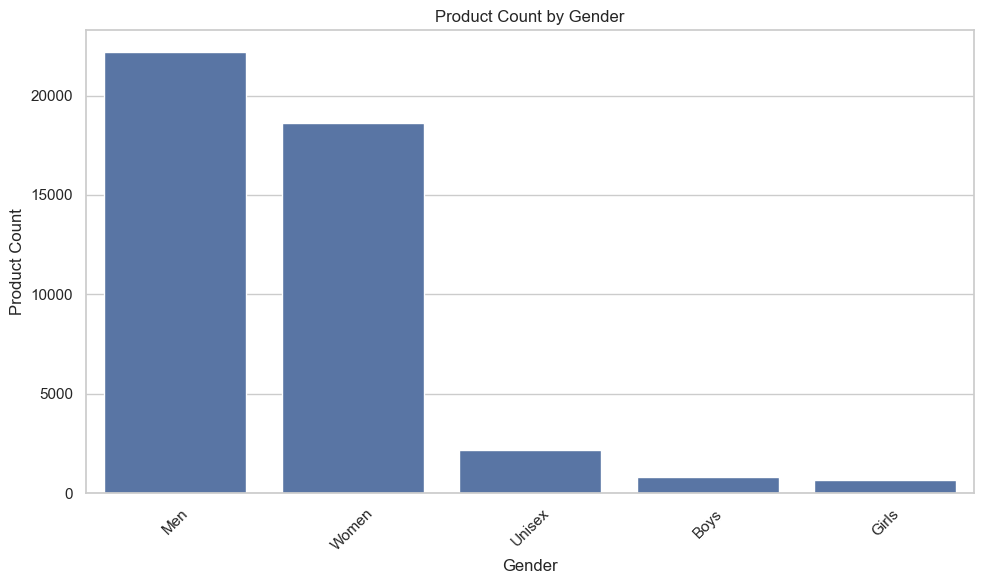

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=gender_counts,
    x="Gender",
    y="Product Count"
)

plt.title("Product Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Product Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Insights
The product catalog is heavily dominated by Adult count 

In [11]:
# Master Category Distribution

master_counts = (
    df["masterCategoryName"]
    .value_counts()
    .reset_index()
)

master_counts.columns = [
    "Master Category",
    "Product Count"
]

display(master_counts)

,Master Category,Product Count
0,Apparel,21400
1,Accessories,11289
2,Footwear,9222
3,Personal Care,2404
4,Free Items,105
5,Sporting Goods,25
6,Home,1


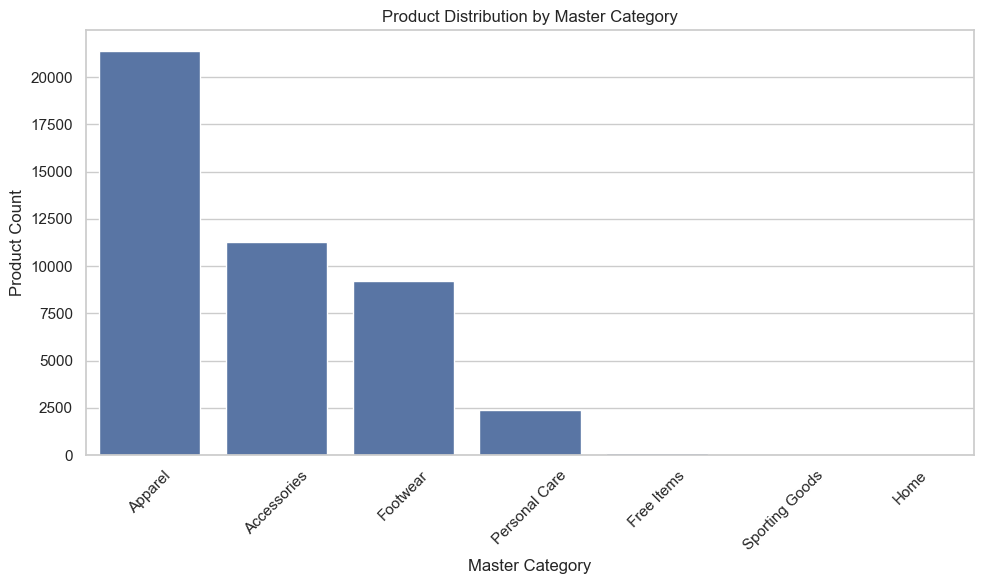

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=master_counts,
    x="Master Category",
    y="Product Count"
)

plt.title("Product Distribution by Master Category")
plt.xlabel("Master Category")
plt.ylabel("Product Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Insights
Appareal, Accessories and Footwear overwhelming drive the catalog volume while catogories like sport goods and Home contain almost negligible products.
The dataset is highly is highly specialised infashion and lifestyle retailer


### Observation

The distribution shows how the 44,446 products are spread across the different master categories. Apparel, Accessories and Footwear account for the majority of the products, while categories such as Home and Sporting Goods contain comparatively fewer products.

### Insight

The dataset is strongly concentrated in fashion-related master categories. This confirms that the dataset is suitable for fashion product analysis and image-based classification. The large number of products in the major categories also provides a substantial pool for selecting a modeling category in Step 4.

In [13]:
# Top Article Types
article_counts = (
    df["articleTypeName"]
    .value_counts()
    .head(20)
    .reset_index()
)

article_counts.columns = [
    "Article Type",
    "Product Count"
]

display(article_counts)

,Article Type,Product Count
0,Tshirts,7070
1,Shirts,3217
2,Casual Shoes,2846
3,Watches,2542
4,Sports Shoes,2036
5,Kurtas,1844
6,Tops,1762
7,Handbags,1759
8,Heels,1323
9,Sunglasses,1073


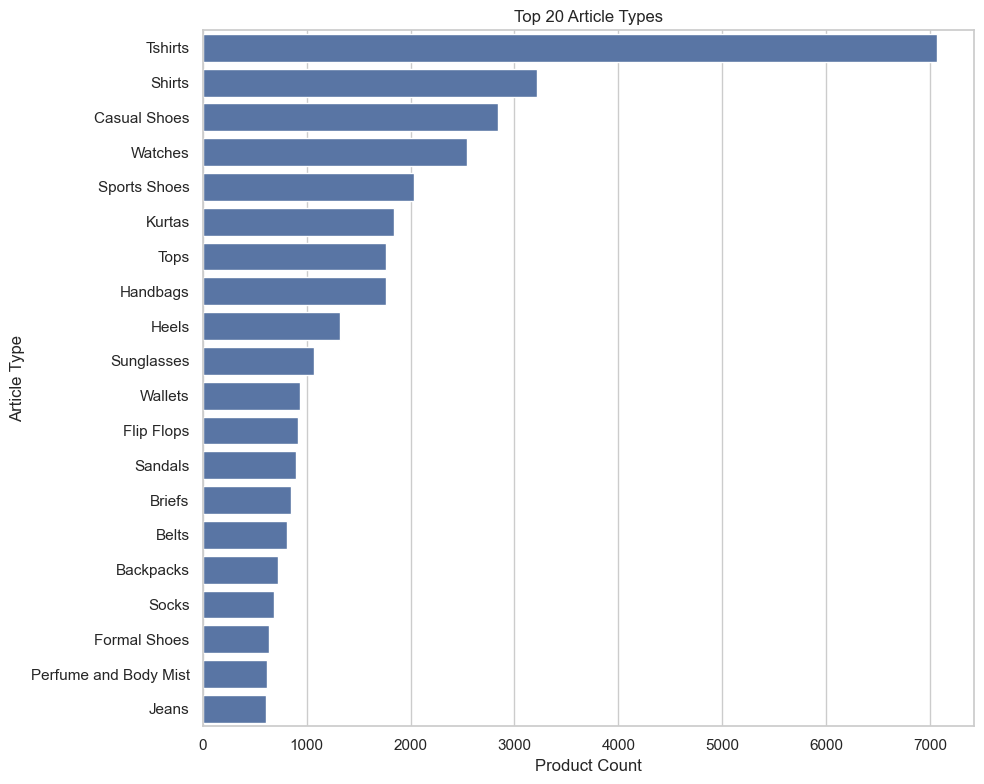

In [14]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=article_counts,
    x="Product Count",
    y="Article Type"
)

plt.title("Top 20 Article Types")
plt.xlabel("Product Count")
plt.ylabel("Article Type")
plt.tight_layout()
plt.show()

### Observation

The dataset contains a wide range of article types, with a relatively small number of article types accounting for a large proportion of the products.

### Insight

The diversity of article types indicates that the dataset contains substantial product-level variation. This is important for image classification because the selected modeling category should contain enough images across meaningful article types while avoiding extremely sparse classes.

In [ ]:
# Top 20 brands

brand_counts = (
    df["brandName"]
    .value_counts()
    .head(20)
    .reset_index()
)

brand_counts.columns = [
    "Brand",
    "Product Count"
]

display(brand_counts)

,Brand,Product Count
0,Nike,2203
1,Puma,2098
2,ADIDAS,1923
3,United Colors of Benetton,1563
4,Fabindia,751
5,Catwalk,744
6,Gini and Jony,721
7,Fastrack,688
8,Wrangler,683
9,Lino Perros,655


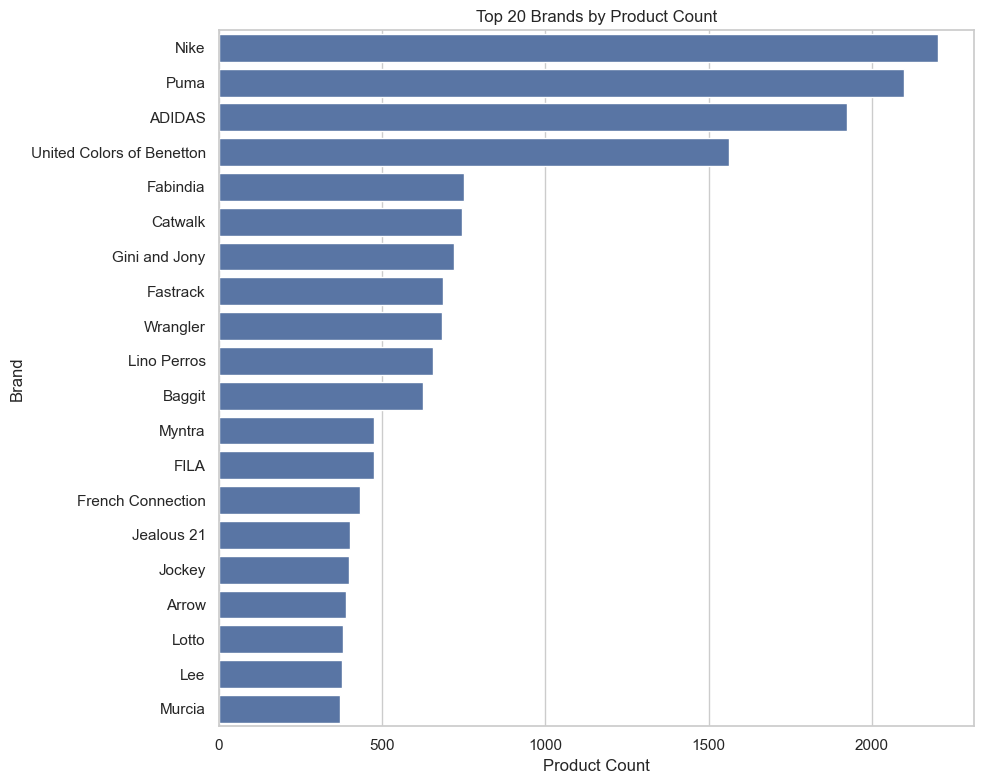

In [23]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=brand_counts,
    x="Product Count",
    y="Brand"
)

plt.title("Top 20 Brands by Product Count")
plt.xlabel("Product Count")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### Observation

The product catalog is distributed across many brands, with the leading brands contributing more products than the remaining brands.

### Insight

The presence of multiple brands suggests that the dataset represents a broad fashion catalog rather than being dominated by a single brand. Brand information can therefore provide useful context during EDA, although it will not be used as the primary target for image classification.

In [17]:
# Base colour Disribution

colour_counts = (
    df["baseColour"]
    .value_counts()
    .head(20)
    .reset_index()
)

colour_counts.columns = [
    "Base Colour",
    "Product Count"
]

display(colour_counts)

,Base Colour,Product Count
0,Black,9732
1,White,5540
2,Blue,4922
3,Brown,3494
4,Grey,2741
5,Red,2458
6,Green,2116
7,Pink,1861
8,Navy Blue,1791
9,Purple,1643


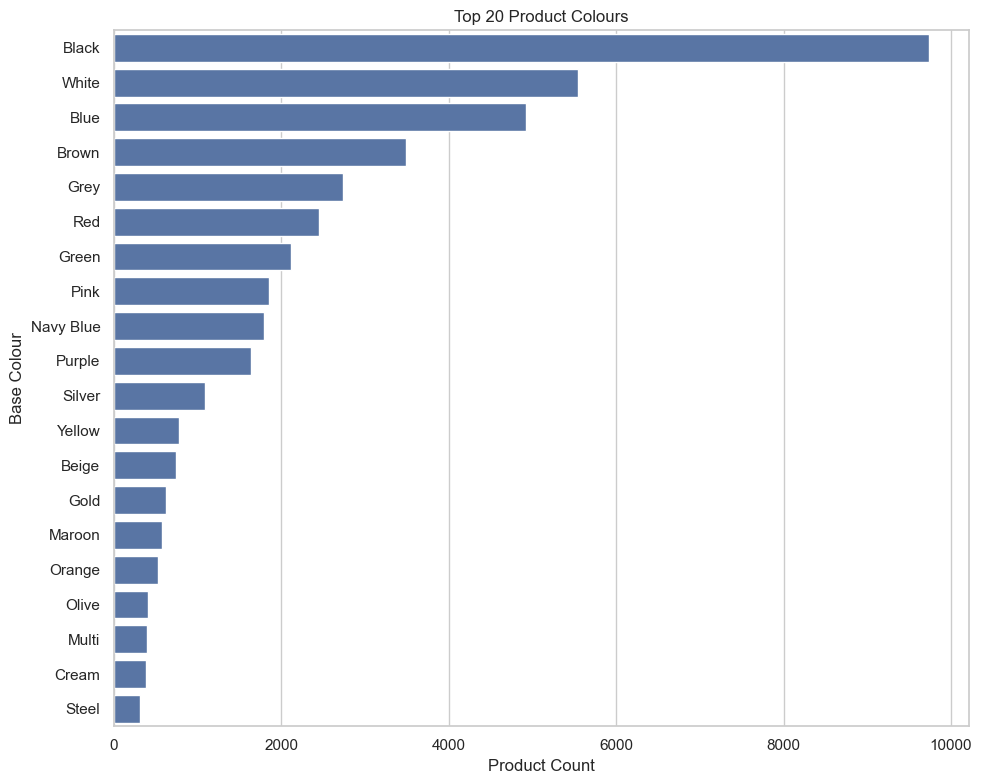

In [24]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=colour_counts,
    x="Product Count",
    y="Base Colour"
)

plt.title("Top 20 Product Colours")
plt.xlabel("Product Count")
plt.ylabel("Base Colour")
plt.tight_layout()
plt.show()

### Observation

The product catalog contains a diverse range of base colours, with certain colours occurring substantially more frequently than others.

### Insight

Colour diversity is relevant to image-based fashion classification because colour can be an important visual feature. However, the imbalance among colours should be considered when interpreting model performance, particularly if colour is used as an auxiliary classification attribute.

In [19]:
# Season Distribution
season_counts = (
    df["season"]
    .value_counts()
    .reset_index()
)

season_counts.columns = [
    "Season",
    "Product Count"
]

display(season_counts)

,Season,Product Count
0,Summer,21476
1,Fall,11445
2,Winter,8519
3,Spring,2985
4,Unknown,21


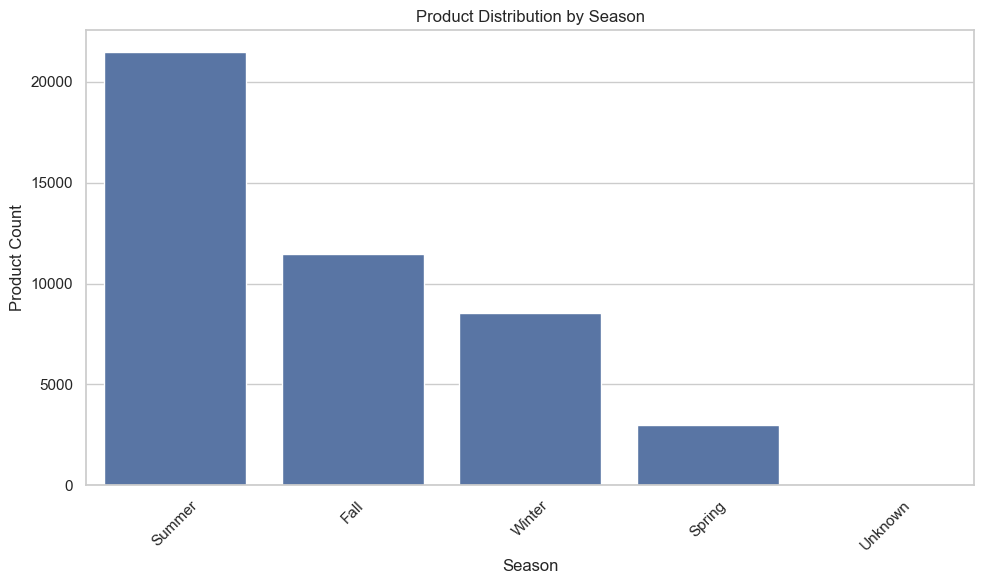

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=season_counts,
    x="Season",
    y="Product Count"
)

plt.title("Product Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Product Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The product distribution varies across seasons, with some seasons contributing substantially more products than others.

### Insight

The seasonal distribution provides context about the composition of the catalog. Seasonal imbalance should be considered when evaluating whether the selected modeling category represents a sufficiently broad range of products.

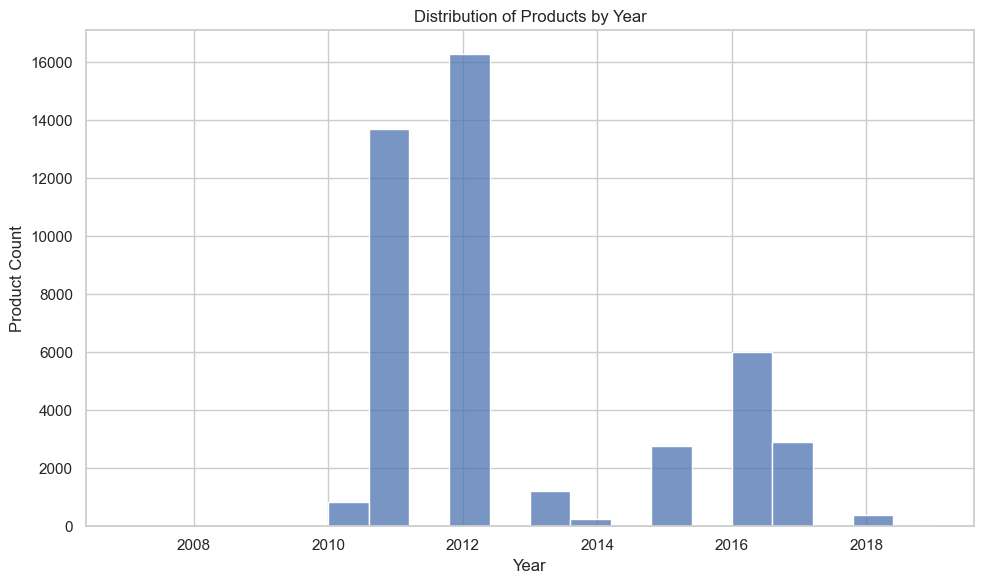

In [26]:
# Year Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="year",
    bins=20
)

plt.title("Distribution of Products by Year")
plt.xlabel("Year")
plt.ylabel("Product Count")
plt.tight_layout()
plt.show()

### Observation

The histogram shows the distribution of products across the available years. The concentration of products within particular years indicates the time period in which most of the catalog records were created.

### Insight

The year distribution helps identify the temporal coverage of the dataset and whether the catalog is concentrated in particular periods. It also provides an opportunity to detect unusually early or late records before modeling.

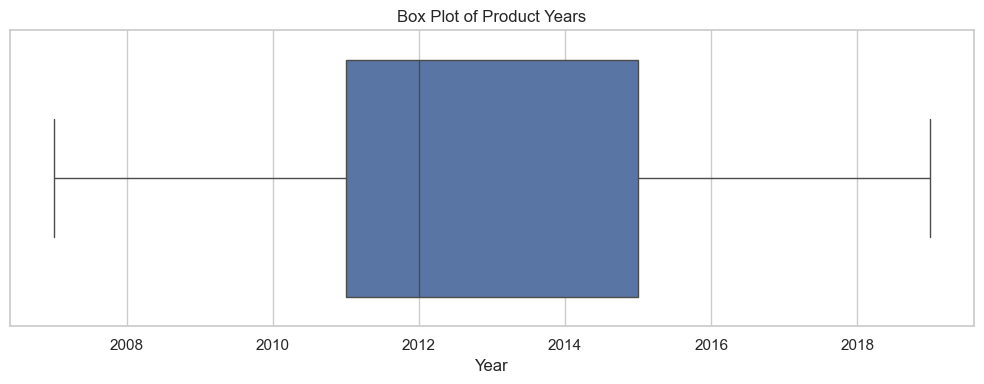

In [27]:
# year Outlier Analysis

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["year"]
)

plt.title("Box Plot of Product Years")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

### Observation

The box plot shows the central distribution of product years and highlights any years that fall outside the typical range.

### Insight

Potential statistical outliers in the year field should be investigated rather than automatically removed. An unusual year may represent a legitimate historical product record, so outlier detection is used here for data-quality assessment rather than automatic deletion.

Bivariant Analysis

In [28]:
# Gender vs master category

gender_category = pd.crosstab(
    df["masterCategoryName"],
    df["gender"]
)

gender_category

gender,Boys,Girls,Men,Unisex,Women
masterCategoryName,,,,,
Accessories,17,28,4426,1497,5321
Apparel,759,567,11355,96,8623
Footwear,54,60,5751,521,2836
Free Items,0,0,53,9,43
Home,0,0,0,1,0
Personal Care,0,0,580,15,1809
Sporting Goods,0,0,0,25,0


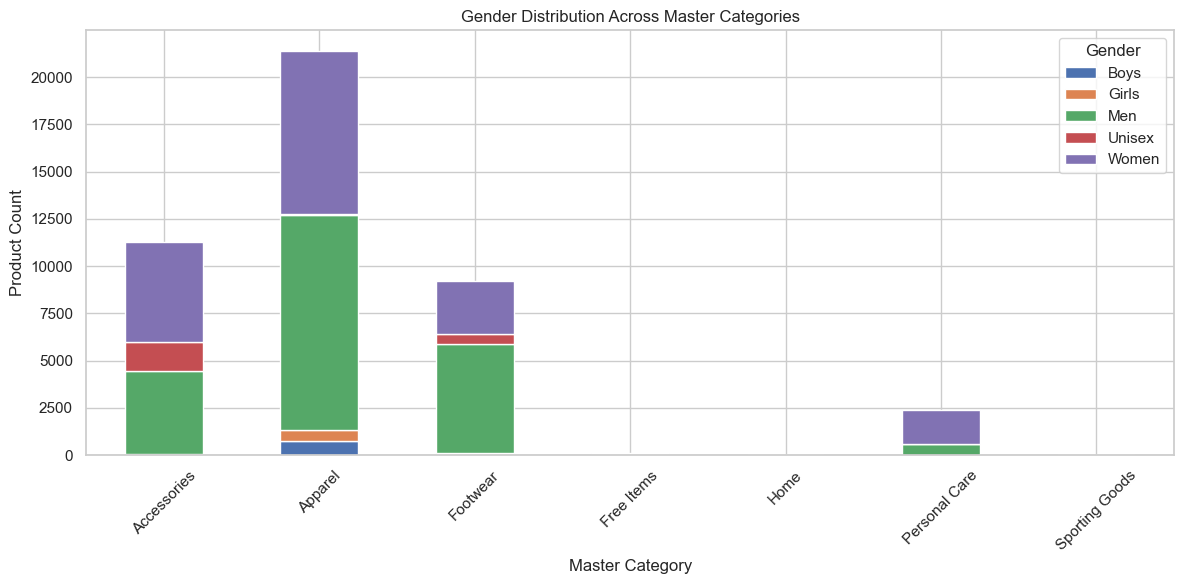

In [29]:
gender_category.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Gender Distribution Across Master Categories")
plt.xlabel("Master Category")
plt.ylabel("Product Count")
plt.xticks(rotation=45)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Observation

The stacked distribution shows how different gender groups contribute to each master category. Some categories are strongly associated with particular gender groups, while others contain products across multiple groups.

### Insight

The relationship between gender and master category is important for Step 4. A suitable modeling category should have substantial product volume and meaningful representation rather than being selected solely because it has the largest overall count.

In [30]:
# Gender vs Season

gender_season = pd.crosstab(
    df["gender"],
    df["season"]
)

display(gender_season)

season,Fall,Spring,Summer,Unknown,Winter
gender,,,,,
Boys,113,6,691,0,20
Girls,81,3,536,0,35
Men,7087,966,10877,8,3227
Unisex,504,99,938,6,617
Women,3660,1911,8434,7,4620


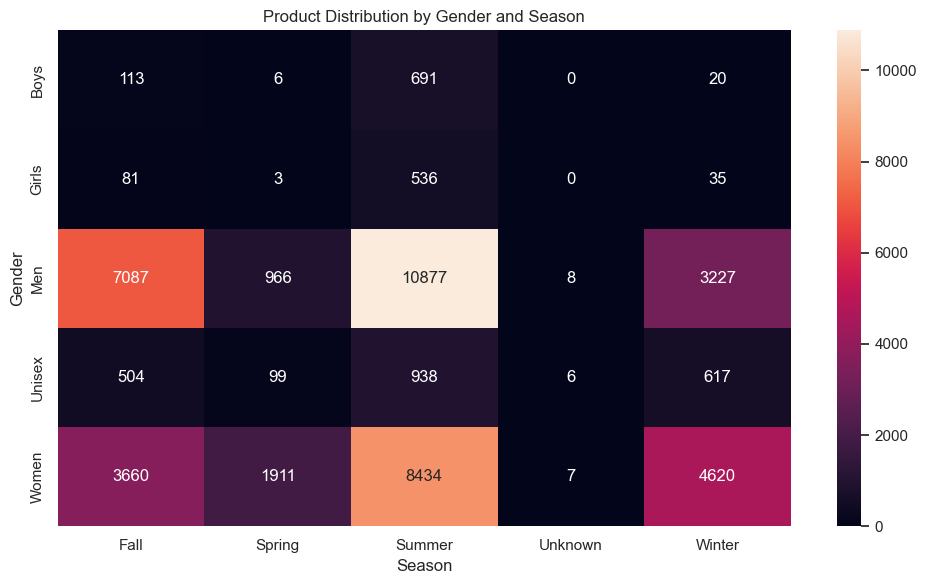

In [31]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    gender_season,
    annot=True,
    fmt="d"
)

plt.title("Product Distribution by Gender and Season")
plt.xlabel("Season")
plt.ylabel("Gender")
plt.tight_layout()
plt.show()

### Observation

The heatmap highlights differences in product volume across gender and season combinations. Some combinations have considerably higher product counts than others.

### Insight

The distribution indicates whether each gender category has sufficient representation across different seasons. This will help us assess the breadth of the Men, Women and Kids categories before selecting the modeling category.

In [32]:
# Colour vs Master category

top_colours = (
    df["baseColour"]
    .value_counts()
    .head(10)
    .index
)

colour_category = pd.crosstab(
    df.loc[
        df["baseColour"].isin(top_colours),
        "masterCategoryName"
    ],
    df.loc[
        df["baseColour"].isin(top_colours),
        "baseColour"
    ]
)

display(colour_category)

baseColour,Black,Blue,Brown,Green,Grey,Navy Blue,Pink,Purple,Red,White
masterCategoryName,,,,,,,,,,
Accessories,3305,712,1321,326,525,232,314,381,466,984
Apparel,3203,3436,565,1467,1610,1270,1107,1001,1432,2795
Footwear,2935,549,1338,201,552,281,151,118,381,1528
Free Items,33,14,2,4,1,1,2,4,5,19
Personal Care,251,208,265,118,52,7,287,139,171,208
Sporting Goods,5,3,3,0,1,0,0,0,3,6


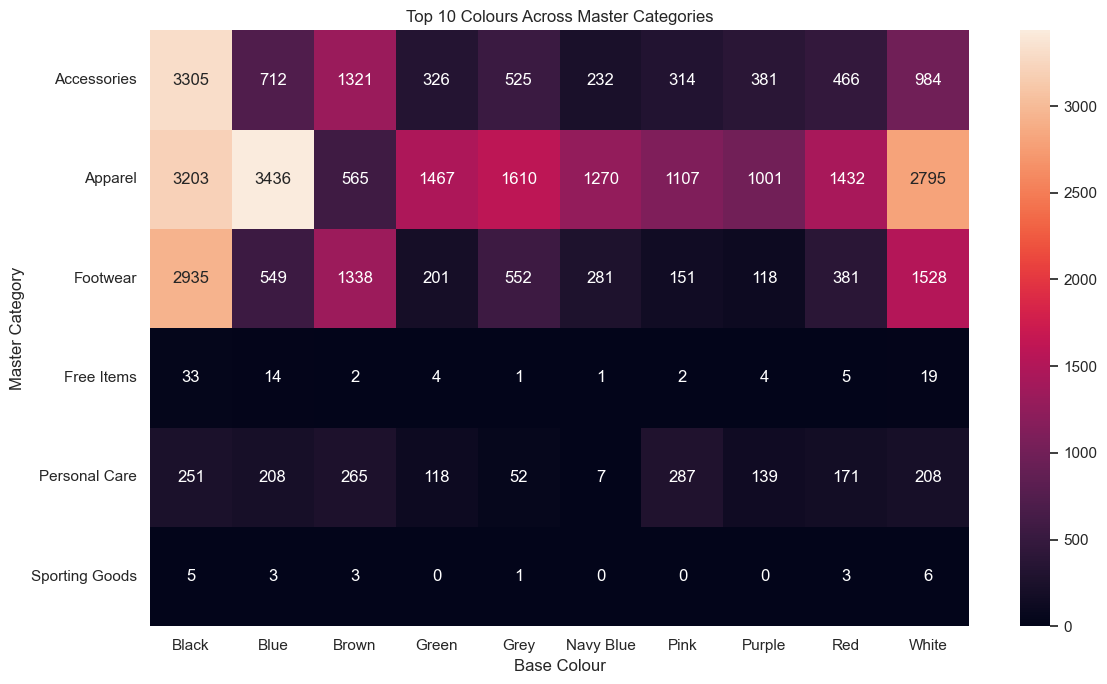

In [33]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    colour_category,
    annot=True,
    fmt="d"
)

plt.title("Top 10 Colours Across Master Categories")
plt.xlabel("Base Colour")
plt.ylabel("Master Category")
plt.tight_layout()
plt.show()

### Observation

The heatmap shows that colour distribution differs across master categories. Some colours are broadly represented, while others are concentrated within particular product categories.

### Insight

Colour is an important visual characteristic of fashion products. The variation across categories suggests that colour information may contribute to distinguishing product classes in an image-based model.

In [36]:
# Year vs Gender Trend

year_gender = (
    df.groupby(["year", "gender"])
    .size()
    .reset_index(name="Product Count")
)

display(year_gender.head())

,year,gender,Product Count
0,2007,Men,2
1,2008,Boys,1
2,2008,Girls,1
3,2008,Men,5
4,2009,Men,16


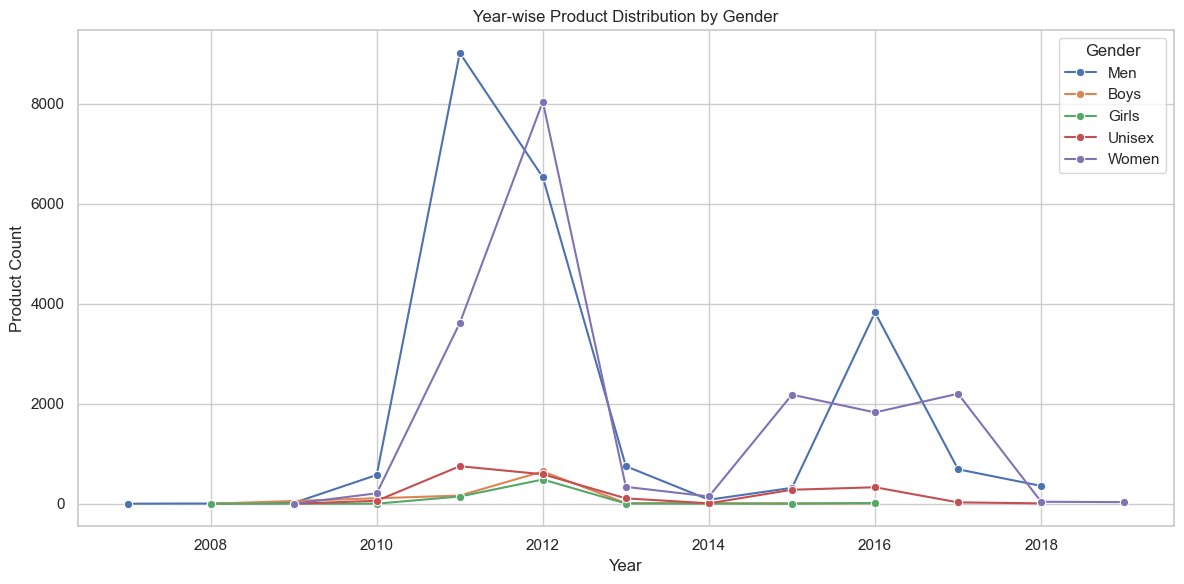

In [37]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_gender,
    x="year",
    y="Product Count",
    hue="gender",
    marker="o"
)

plt.title("Year-wise Product Distribution by Gender")
plt.xlabel("Year")
plt.ylabel("Product Count")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Observation

The line chart shows how product volume for each gender category changes across the available years.

### Insight

The trend provides additional evidence for evaluating the consistency and historical coverage of the Men, Women and Kids categories. A category with strong representation across the dataset's time range may provide a more diverse modeling dataset.

Multivariate Analysis

In [38]:
# Gender vs Master Category vs Season

gender_category_season = pd.crosstab(
    [
        df["gender"],
        df["masterCategoryName"]
    ],
    df["season"]
)

display(gender_category_season)

season                     Fall  Spring  Summer  Unknown  Winter
gender masterCategoryName                                       
Boys   Accessories            2       0       7        0       8
       Apparel               82       1     674        0       2
       Footwear              29       5      10        0      10
Girls  Accessories            3       0       8        0      17
       Apparel               66       0     500        0       1
       Footwear              12       3      28        0      17
Men    Accessories          446      32    1679        0    2269
       Apparel             4817     124    6107        1     306
       Footwear            1824     231    3075        7     614
       Free Items             0       3      12        0      38
       Personal Care          0     576       4        0       0
Unisex Accessories          296      49     611        0     541
       Apparel               33       0      62        0       1
       Footwear             163      35     251        6      66
       Free Items             0       0       2        0       7
       Home                   1       0       0        0       0
       Personal Care          0      15       0        0       0
       Sporting Goods        11       0      12        0       2
Women  Accessories          484      28    2263        0    2546
       Apparel             2724      13    5325        0     561
       Footwear             452      93     783        7    1501
       Free Items             0       2      30        0      11
       Personal Care          0    1775      33        0       1

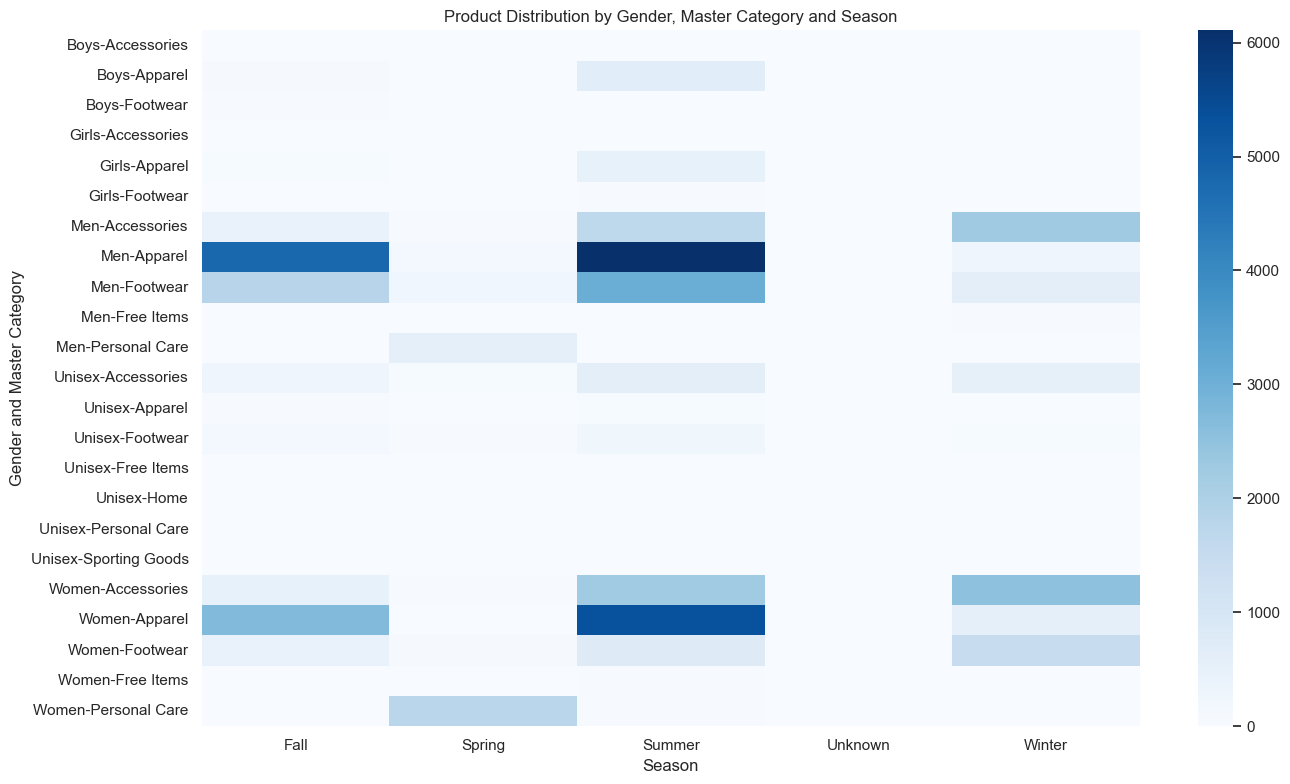

In [39]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    gender_category_season,
    annot=False,
    cmap="Blues"
)

plt.title(
    "Product Distribution by Gender, Master Category and Season"
)
plt.xlabel("Season")
plt.ylabel("Gender and Master Category")
plt.tight_layout()
plt.show()

### Observation

The multivariate heatmap combines gender, master category and season, revealing how product volume varies across these three dimensions.

### Insight

This combined view helps identify whether a gender category has broad representation across product categories and seasons. Such breadth is useful when selecting a robust category for image classification.

In [40]:
# Gender vs Article type vs Master Category
top_articles = (
    df["articleTypeName"]
    .value_counts()
    .head(15)
    .index
)

article_gender_category = pd.crosstab(
    [
        df.loc[
            df["articleTypeName"].isin(top_articles),
            "gender"
        ],
        df.loc[
            df["articleTypeName"].isin(top_articles),
            "masterCategoryName"
        ]
    ],
    df.loc[
        df["articleTypeName"].isin(top_articles),
        "articleTypeName"
    ]
)

display(article_gender_category)

articleTypeName            Belts  Briefs  Casual Shoes  Flip Flops  Handbags  \
gender masterCategoryName                                                      
Boys   Accessories             0       0             0           0         0   
       Apparel                 0       0             0           0         0   
       Footwear                0       0            24          16         0   
Girls  Accessories             0       0             0           0         0   
       Apparel                 0       0             0           0         0   
       Footwear                0       0            14           7         0   
Men    Accessories           538       0             0           0         5   
       Apparel                 3     564             0           0         0   
       Footwear                0       0          2247         496         0   
       Free Items              0       0             0           0         0   
Unisex Accessories             9       0             0           0        65   
       Apparel                 0       0             0           0         0   
       Footwear                0       0           228         150         0   
Women  Accessories           263       0             0           0      1687   
       Apparel                 0     285             0           0         0   
       Footwear                0       0           333         247         0   
       Free Items              0       0             0           0         2   

articleTypeName            Heels  Kurtas  Sandals  Shirts  Sports Shoes  \
gender masterCategoryName                                                 
Boys   Accessories             0       0        0       0             0   
       Apparel                 0       5        0      78             0   
       Footwear                0       0       11       0             3   
Girls  Accessories             0       0        0       0             0   
       Apparel                 0       0        0       1             0   
       Footwear                0       0       39       0             0   
Men    Accessories             0       0        0       0             0   
       Apparel                 0      78        0    2844             0   
       Footwear                1       0      749       0          1590   
       Free Items              0       0        0       0             0   
Unisex Accessories             0       0        0       0             0   
       Apparel                 0       0        0       0             0   
       Footwear                0       0       94       0            43   
Women  Accessories             0       0        0       0             0   
       Apparel                 0    1761        0     294             0   
       Footwear             1322       0        4       0           400   
       Free Items              0       0        0       0             0   

articleTypeName            Sunglasses  Tops  Tshirts  Wallets  Watches  
gender masterCategoryName                                               
Boys   Accessories                  1     0        0        0        8  
       Apparel                      0     0      531        0        0  
       Footwear                     0     0        0        0        0  
Girls  Accessories                  2     0        0        0       16  
       Apparel                      0   229      106        0        0  
       Footwear                     0     0        0        0        0  
Men    Accessories                598     0        1      449     1473  
       Apparel                      0     1     5245        0        0  
       Footwear                     0     0        0        0        0  
       Free Items                   0     0        0        1        0  
Unisex Accessories                150     0        0       21      143  
       Apparel                      0     0       71        0        0  
       Footwear                

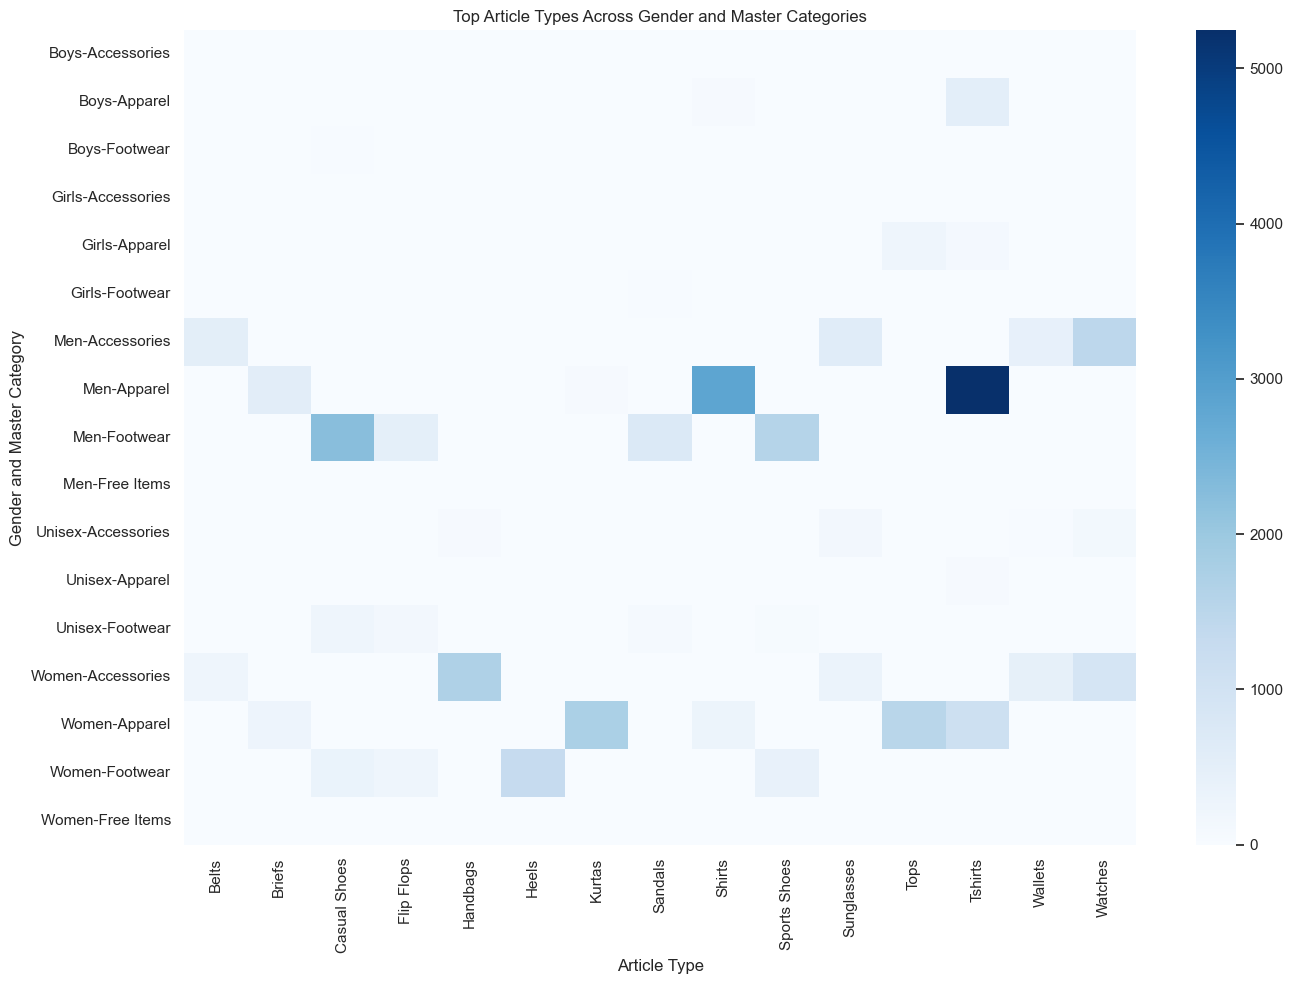

In [41]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    article_gender_category,
    annot=False,
    cmap="Blues"
)

plt.title(
    "Top Article Types Across Gender and Master Categories"
)
plt.xlabel("Article Type")
plt.ylabel("Gender and Master Category")
plt.tight_layout()
plt.show()

### Observation

The heatmap demonstrates how the most common article types are distributed across gender and master categories.

### Insight

The distribution of article types provides an important measure of product diversity. A suitable modeling category should contain enough distinct article types while maintaining sufficient representation for image classification.

In [42]:
# Gender vs Colour vs Master Category

top_colours = (
    df["baseColour"]
    .value_counts()
    .head(8)
    .index
)

colour_gender_category = pd.crosstab(
    [
        df.loc[
            df["baseColour"].isin(top_colours),
            "gender"
        ],
        df.loc[
            df["baseColour"].isin(top_colours),
            "masterCategoryName"
        ]
    ],
    df.loc[
        df["baseColour"].isin(top_colours),
        "baseColour"
    ]
)

display(colour_gender_category)

baseColour                 Black  Blue  Brown  Green  Grey  Pink  Red  White
gender masterCategoryName                                                   
Boys   Accessories             2     6      0      2     0     0    1      3
       Apparel                73   140      5     75    29     9   96    153
       Footwear                8    13      5      5     2     0   10      1
Girls  Accessories             1     2      1      2     0     9    0      8
       Apparel                38    91      1     38     5   138   30     99
       Footwear                2     9      1      3     1    20    7      2
Men    Accessories          1790   228    627     48   219    14   96    430
       Apparel              1845  2046    286    720  1178   130  846   1534
       Footwear             2066   287    995    103   374     0  177   1084
       Free Items             23     5      2      2     0     0    3     10
       Personal Care         161   114     41     38    39     0   39     45
Unisex Accessories           602   182     97     66   117    27  108     72
       Apparel                15    24      5     13     2     8    7      7
       Footwear              147    50     25     38    23    18   73     54
       Free Items              2     4      0      0     0     0    0      3
       Personal Care           3     0      0      0     0     0    1      0
       Sporting Goods          5     3      3      0     1     0    3      6
Women  Accessories           910   294    596    208   189   264  261    471
       Apparel              1232  1135    268    621   396   822  453   1002
       Footwear              712   190    312     52   152   113  114    387
       Free Items              8     5      0      2     1     2    2      6
       Personal Care          87    94    224     80    13   287  131    163

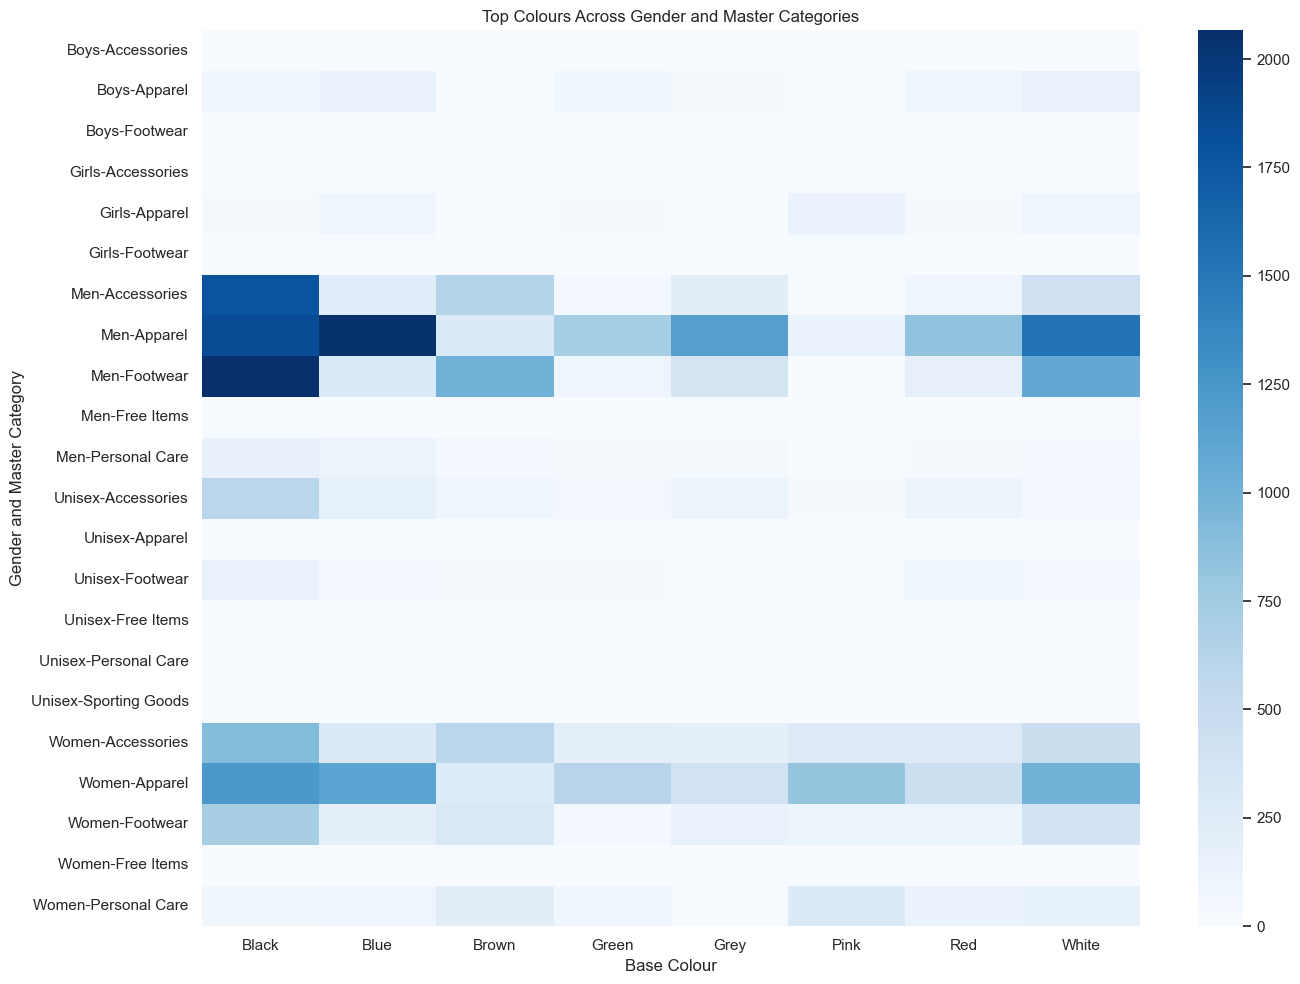

In [43]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    colour_gender_category,
    annot=False,
    cmap="Blues"
)

plt.title(
    "Top Colours Across Gender and Master Categories"
)
plt.xlabel("Base Colour")
plt.ylabel("Gender and Master Category")
plt.tight_layout()
plt.show()

### Observation

The multivariate heatmap shows how the most common colours are distributed across gender and master categories.

### Insight

The interaction between gender, product category and colour provides evidence of the visual diversity present in the dataset. This is relevant to image classification because the selected category should contain sufficient visual variation rather than a narrow set of product characteristics.

Gender distribution
Master category distribution
Gender × master category
Gender × season

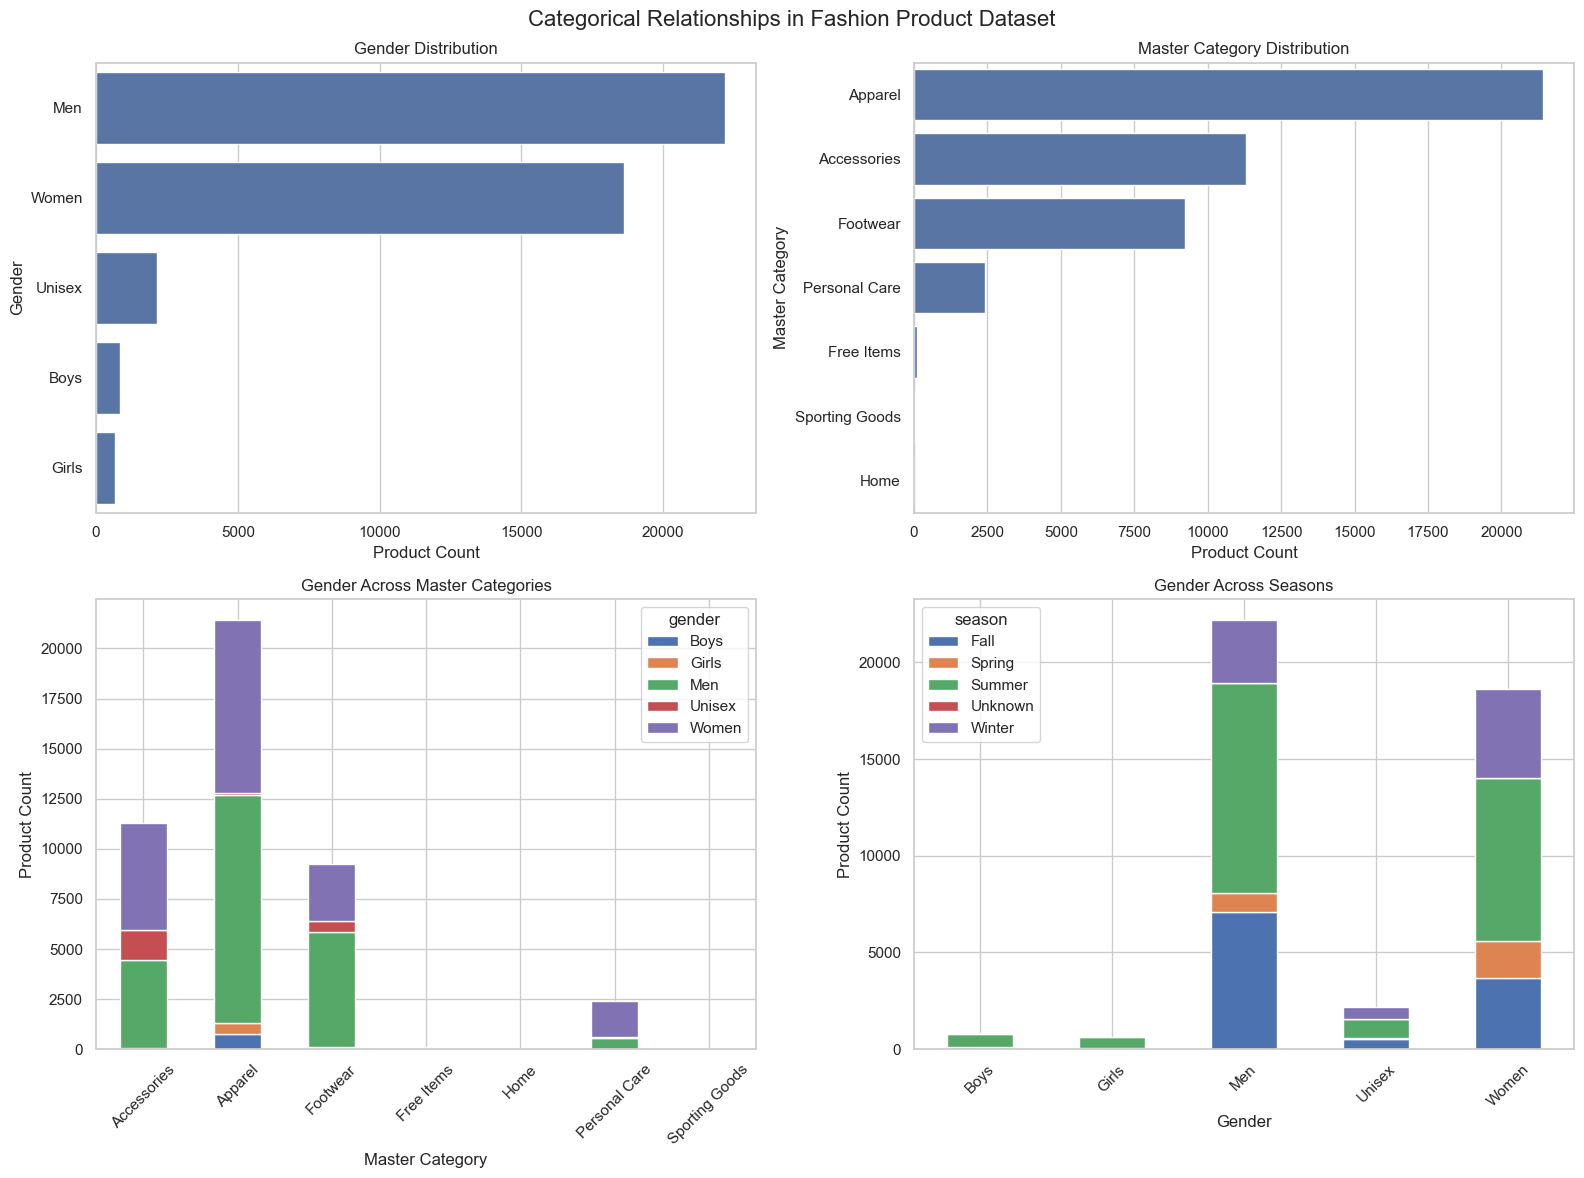

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Gender distribution
gender_counts = df["gender"].value_counts()

sns.barplot(
    x=gender_counts.values,
    y=gender_counts.index,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Gender Distribution")
axes[0, 0].set_xlabel("Product Count")
axes[0, 0].set_ylabel("Gender")


# 2. Master category distribution
master_counts = df["masterCategoryName"].value_counts()

sns.barplot(
    x=master_counts.values,
    y=master_counts.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Master Category Distribution")
axes[0, 1].set_xlabel("Product Count")
axes[0, 1].set_ylabel("Master Category")


# 3. Gender × Master Category
gender_category = pd.crosstab(
    df["masterCategoryName"],
    df["gender"]
)

gender_category.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Gender Across Master Categories")
axes[1, 0].set_xlabel("Master Category")
axes[1, 0].set_ylabel("Product Count")
axes[1, 0].tick_params(axis="x", rotation=45)


# 4. Gender × Season
gender_season = pd.crosstab(
    df["gender"],
    df["season"]
)

gender_season.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Gender Across Seasons")
axes[1, 1].set_xlabel("Gender")
axes[1, 1].set_ylabel("Product Count")
axes[1, 1].tick_params(axis="x", rotation=45)


plt.suptitle(
    "Categorical Relationships in Fashion Product Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Observation

The multi-plot grid provides a consolidated view of gender distribution, master-category composition, and the relationships between gender, master category and season.

The first two plots show the overall structure of the product catalog, while the stacked plots reveal how products are distributed across gender and category combinations.

## Insight

This combined categorical analysis is particularly useful for Step 4 because the modeling category should not be selected only from its overall product count. Gender representation, category diversity and seasonal coverage should all be considered when comparing Men, Women and Kids.

The visualization also helps identify potential class imbalance that may influence the choice of the final modeling category.

EDA Summary

# EDA Summary and Category Selection Criteria

The EDA findings will be used to compare the Men, Women and Kids categories based on:

- Product volume
- Article-type diversity
- Master-category representation
- Colour diversity
- Seasonal representation
- Year-wise coverage
- Data completeness
- Suitability for image classification

The category with the strongest overall evidence will be selected as the single modeling category in Step 4.

Category Selection

In [48]:
gender_values = (
    df["gender"]
    .value_counts(dropna=False)
    .reset_index()
)

gender_values.columns = [
    "Gender",
    "Product Count"
]

display(gender_values)

,Gender,Product Count
0,Men,22165
1,Women,18632
2,Unisex,2164
3,Boys,830
4,Girls,655


In [51]:
# Group Boys and Girls as Kids
df["modeling_category"] = df["gender"].replace({
    "Boys": "Kids",
    "Girls": "Kids"
})

In [ ]:
# modeling Category and validate category

category_counts = (
    df["modeling_category"]
    .value_counts()
    .reindex(
        ["Men", "Women", "Kids", "Unisex"],
        fill_value=0
    )
)

display(category_counts)

modeling_category
Men       22165
Women     18632
Kids       1485
Unisex     2164
Name: count, dtype: int64

group Boys + Girls as Kids, but do it in a new column, not by changing gender.

In [54]:
# Compare only the required modeling categories

modeling_counts = (
    df[df["modeling_category"].isin(["Men", "Women", "Kids"])]
    ["modeling_category"]
    .value_counts()
    .reindex(
        ["Men", "Women", "Kids"],
        fill_value=0
    )
)

display(modeling_counts)

modeling_category
Men      22165
Women    18632
Kids      1485
Name: count, dtype: int64

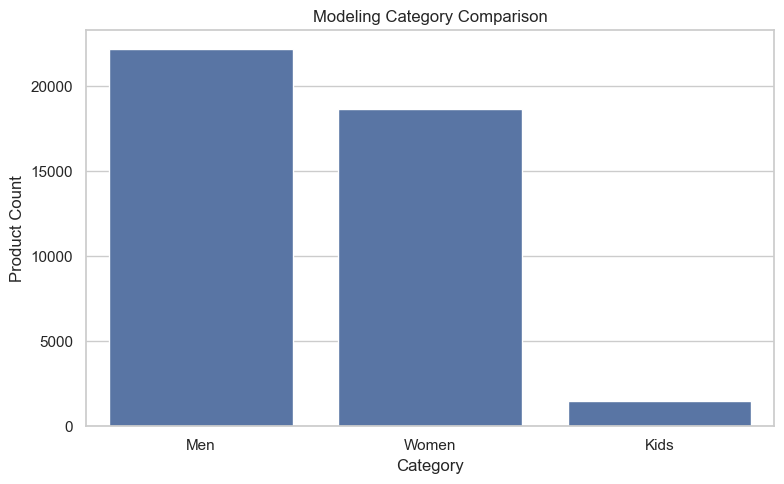

In [55]:
# Visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    x=modeling_counts.index,
    y=modeling_counts.values
)

plt.title("Modeling Category Comparison")
plt.xlabel("Category")
plt.ylabel("Product Count")
plt.tight_layout()
plt.show()

## Category Selection Rationale

The modeling categories were standardized into Men, Women and Kids. Boys and Girls were grouped under Kids to align with the project requirement, while Unisex products were retained separately and excluded from the three-category comparison.

The final category will be selected based on:

- Product volume
- Article-type diversity
- Master-category representation
- Colour diversity
- Seasonal coverage
- Image availability
- Suitability for classification and recommendation modeling

In [ ]:
# Category Selection

category_article_summary = (
    df[df["modeling_category"].isin(["Men", "Women", "Kids"])]
    .groupby("modeling_category")["articleTypeName"]
    .nunique()
    .reindex(["Men", "Women", "Kids"])
)

category_master_summary = (
    df[df["modeling_category"].isin(["Men", "Women", "Kids"])]
    .groupby("modeling_category")["masterCategoryName"]
    .nunique()
    .reindex(["Men", "Women", "Kids"])
)

category_colour_summary = (
    df[df["modeling_category"].isin(["Men", "Women", "Kids"])]
    .groupby("modeling_category")["baseColour"]
    .nunique()
    .reindex(["Men", "Women", "Kids"])
)

category_comparison = pd.DataFrame({
    "Product Count": modeling_counts,
    "Article Type Count": category_article_summary,
    "Master Category Count": category_master_summary,
    "Colour Count": category_colour_summary
})

display(category_comparison)

,Product Count,Article Type Count,Master Category Count,Colour Count
modeling_category,,,,
Men,22165,69,5,41
Women,18632,112,5,47
Kids,1485,34,3,31


18,632 products → very large modeling dataset
112 article types → highest product diversity
5 master categories → broadest category coverage, tied with Men
47 colours → highest colour diversity
Compared with Kids, Women has substantially more images and much greater visual/product diversity.
Compared with Men, Women has fewer total products, but much higher article-type and colour diversity, which is valuable for a fashion image-classification and recommendation system.

Women provides the best balance between dataset size and product/visual diversity.

In [ ]:
# selected category - Women

selected_category = "Women"

df_selected = df[
    df["modeling_category"] == selected_category
].copy()

print("Selected category:", selected_category)

print("Filtered dataset shape:", df_selected.shape)

Selected category: Women
Filtered dataset shape: (18632, 17)


In [58]:
# Modelling count
print(
    df_selected["modeling_category"]
    .value_counts()
)

modeling_category
Women    18632
Name: count, dtype: int64


In [59]:
# validate gender values
print(
    df_selected["gender"]
    .value_counts()
)

gender
Women    18632
Name: count, dtype: int64


In [ ]:
# check selected datset
print("Missing values:", df_selected.isnull().sum().sum())
print("Duplicate product IDs:", df_selected["id"].duplicated().sum())
print("Duplicate filenames:", df_selected["filename"].duplicated().sum())

Missing values: 0
Duplicate product IDs: 0
Duplicate filenames: 0


In [61]:
# save modeling dataset

df_selected.to_csv(
    "fashion_products_selected_v2.csv",
    index=False
)

print("Selected category dataset saved successfully.")
print("Shape:", df_selected.shape)

Selected category dataset saved successfully.
Shape: (18632, 17)


In [62]:
display(df_selected.head())

,id,productDisplayName,brandName,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,filename,imageURL,masterCategoryName,subCategoryName,articleTypeName,modeling_category
0,57896,Femella Women Off White Shorts,Femella,Women,"{'id': 9, 'typeName': 'Apparel', 'active': Tru...","{'id': 29, 'typeName': 'Bottomwear', 'active':...","{'id': 72, 'typeName': 'Shorts', 'active': Tru...",Off White,Summer,2012,Casual,57896.jpg,http://assets.myntassets.com/v1/images/style/p...,Apparel,Bottomwear,Shorts,Women
3,51041,Enamor Women Ivory Coloured Briefs,Enamor,Women,"{'id': 9, 'typeName': 'Apparel', 'active': Tru...","{'id': 136, 'typeName': 'Innerwear', 'active':...","{'id': 137, 'typeName': 'Briefs', 'active': Tr...",White,Summer,2017,Casual,51041.jpg,http://assets.myntassets.com/v1/images/style/p...,Apparel,Innerwear,Briefs,Women
8,59471,Lucera Silver Ring,Lucera,Women,"{'id': 1, 'typeName': 'Accessories', 'active':...","{'id': 146, 'typeName': 'Jewellery', 'active':...","{'id': 229, 'typeName': 'Ring', 'active': True...",Silver,Summer,2013,Casual,59471.jpg,http://assets.myntassets.com/v1/images/style/p...,Accessories,Jewellery,Ring,Women
9,42397,Flying Machine Women Black T-shirt,Flying Machine,Women,"{'id': 9, 'typeName': 'Apparel', 'active': Tru...","{'id': 31, 'typeName': 'Topwear', 'active': Tr...","{'id': 90, 'typeName': 'Tshirts', 'active': Tr...",Black,Summer,2012,Casual,42397.jpg,http://assets.myntassets.com/v1/images/style/p...,Apparel,Topwear,Tshirts,Women
11,38162,Miami Blues Women Sunglasses,Miami Blues,Women,"{'id': 1, 'typeName': 'Accessories', 'active':...","{'id': 15, 'typeName': 'Eyewear', 'active': Tr...","{'id': 51, 'typeName': 'Sunglasses', 'active':...",Brown,Winter,2016,Casual,38162.jpg,http://assets.myntassets.com/v1/images/style/p...,Accessories,Eyewear,Sunglasses,Women


# Category Selection

Based on the EDA, the Women category was selected as the single modeling category.

The category comparison showed:

- 18,632 products
- 112 article types
- 5 master categories
- 47 colour categories

Women was selected because it provides a strong combination of dataset size and product diversity. It has substantially more article-type and colour diversity than the Kids category and greater diversity than the Men category while still providing a sufficiently large dataset for deep-learning-based image classification.

Boys and Girls were grouped into the Kids category for the category comparison, while Unisex products were retained separately and excluded from the Men/Women/Kids selection.

The final dataset was filtered to contain only Women products. This focused dataset will be used for the subsequent classification and recommendation modeling stages.